Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 4.3 MB/s eta 0:00:00
OUTPUT: /content/drive/MyDrive/FYP/data/processed/noise_sensitivity_r1 | device cpu
clean dataset (53138, 180) (53138, 4) | order identical to the artifact
clean in-sample accuracy (3-model ensemble): 0.983
noise pools disjoint from each other and from the test pool; achieved SNR within 0.5 dB: OK
bw 24 acc 0.9831 | changed 0.0007 | 19 s
bw 18 acc 0.983 | changed 0.0015 | 35 s
bw 12 acc 0.9821 | changed 0.0033 | 57 s
bw 6 acc 0.9801 | changed 0.0073 | 78 s
bw 0 acc 0.9737 | changed 0.0164 | 101 s
bw -6 acc 0.9543 | changed 0.04 | 118 s
em 24 acc 0.9818 | changed 0.0056 | 139 s
em 18 acc 0.9749 | changed 0.0153 | 161 s
em 12 acc 0.946 | changed 0.0475 | 182 s
em 6 acc 0.8705 | changed 0.1254 | 204 s
em 0 acc 0.7222 | changed 0.276 | 225 s
em -6 acc 0.5138 | changed 0.485 | 248 s
ma 24 acc 0.983 | changed 0.0024 | 269 s
ma 18 acc 0.9828 | changed 0.0056 | 291 s
ma 12 acc 0.9785 | cha

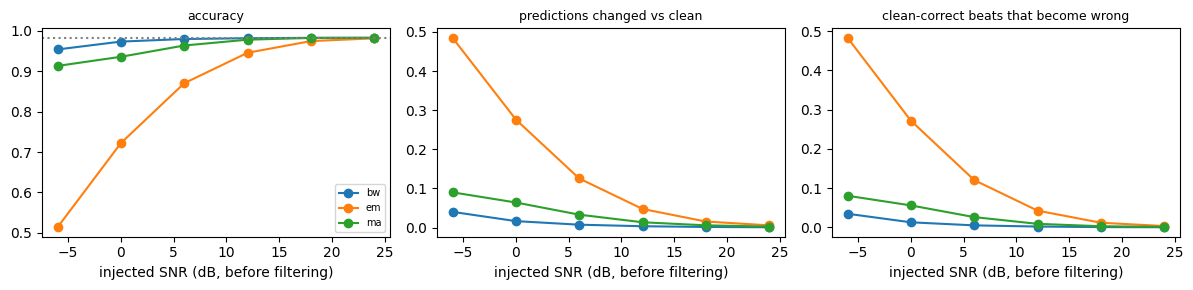

In [4]:
# =====================================================================================
# 06_classifier_noise_sensitivity.ipynb  --  DIAGNOSTIC ONLY (in-sample): how do the saved FINAL models react to injected noise on DS1?
# The final models (cnn_ds1_seed42/43/44.pt) were trained on ALL of DS1, so every number here is IN-SAMPLE. Use it to check the
# noise pipeline and to see which noise types change the classifier's predictions; do NOT use it to claim robustness on unseen
# patients and do NOT use it to pick a gate on its own. DS2 and the test noise pool are not read.
# Uses the same preprocessing as training: src.segment.build_dataset(..., signal_fn=<noise>) injects noise BEFORE the 0.5-40 Hz band-pass.
# =====================================================================================

# ===== CELL 1: setup =====
from google.colab import drive
drive.mount('/content/drive')
!pip install -q wfdb
import os, sys, json, zlib, hashlib, time
os.chdir('/content/drive/MyDrive/FYP'); sys.path.insert(0, os.getcwd())

import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from scipy.special import softmax
from src import config as C
from src.data import load_beats, load_signal
from src.noise import NOISE_TYPES, load_noise, CHUNK, BLOCK, chunk_starts
from src.segment import build_dataset
from src.model import BeatCNN
from src.train2 import get_logits, DEVICE

ARTIFACT = C.PROC / 'oof_ds1_v6_subjectfolds.npz'            # used only to check beat order; no OOF number is used
ARTIFACT_SHA256 = '7138c8cf977be01aa1116ab78cab49da344413fd8ec5d8551846f39e37ab1e6c'
SEEDS, SNRS = [42, 43, 44], [24, 18, 12, 6, 0, -6]
sha256_of = lambda p: hashlib.sha256(open(p, 'rb').read()).hexdigest()
assert sha256_of(ARTIFACT) == ARTIFACT_SHA256
k_ver = 1
while (C.PROC / f'noise_sensitivity_r{k_ver}').exists():
    k_ver += 1
OUT = C.PROC / f'noise_sensitivity_r{k_ver}'; OUT.mkdir(parents=True, exist_ok=False)
print('OUTPUT:', OUT, '| device', DEVICE)

d = np.load(ARTIFACT); y_art, rec_art, ridx_art = d['y'], d['rec'], d['ridx']
tbl = load_beats(); d1 = tbl[tbl.split == 'DS1']
X0, RR0, y, rec, ridx = build_dataset(d1)                     # clean DS1, identical to training preprocessing
assert np.array_equal(y, y_art) and np.array_equal(rec, rec_art) and np.array_equal(ridx, ridx_art), 'beat order differs from the artifact'
print('clean dataset', X0.shape, RR0.shape, '| order identical to the artifact')

models = []
for sd in SEEDS:
    m = BeatCNN().to(DEVICE)
    m.load_state_dict(torch.load(C.PROC / f'cnn_ds1_seed{sd}.pt', map_location=DEVICE)); m.eval(); models.append(m)
def ens_logits(X, RR): return np.mean([get_logits(m, X, RR) for m in models], axis=0)

L0 = ens_logits(X0, RR0); pred0 = L0.argmax(1); ok0 = pred0 == y
print('clean in-sample accuracy (3-model ensemble):', ok0.mean().round(4))
assert ok0.mean() > 0.9, 'in-sample clean accuracy is unexpectedly low: wrong checkpoints or preprocessing?'


# ===== CELL 2: development noise (pool B, same definition as notebook 05) =====
_ps = {}
def pool_starts(kind, label):
    if (kind, label) not in _ps:
        nz = load_noise(kind); st = []
        for b in range(len(nz) // BLOCK):
            if b % 4 == (0 if label == 'A' else 2):
                st += list(range(b * BLOCK, (b + 1) * BLOCK - CHUNK + 1, CHUNK))
        _ps[(kind, label)] = np.array(st)
    return _ps[(kind, label)]

def noisy(rec_id, sig, kind, snr, label):
    rng = np.random.default_rng(zlib.crc32(f'sqi-{kind}-{snr}-{rec_id}-{label}'.encode()))
    nz = load_noise(kind); st = pool_starts(kind, label)
    z = np.concatenate([nz[s:s + CHUNK] for s in rng.choice(st, int(np.ceil(len(sig) / CHUNK)), replace=True)])[:len(sig)]
    z = z - z.mean()
    return (sig + np.sqrt(np.var(sig) / (np.var(z) * 10 ** (snr / 10))) * z).astype(np.float32)

sig106 = load_signal(106)
for kind in NOISE_TYPES:
    A, B = set(pool_starts(kind, 'A')), set(pool_starts(kind, 'B')); test = set(chunk_starts(len(load_noise(kind)), 'test'))
    assert not (A & B) and not ((A | B) & test)
    for snr in [24, -6]:
        got = 10 * np.log10(np.var(sig106) / np.var(noisy(106, sig106, kind, snr, 'B') - sig106)); assert abs(got - snr) < 0.5
print('noise pools disjoint from each other and from the test pool; achieved SNR within 0.5 dB: OK')


# ===== CELL 3: predictions under noise (all DS1 beats, 3-model ensemble) =====
rows, t0 = [], time.time()
rows.append(dict(kind='clean', snr=np.nan, n_beats=len(y), n_records=len(np.unique(rec)), acc=ok0.mean(),
                 **{f'recall_{c}': (pred0[y == i] == i).mean() for i, c in enumerate(C.CLASSES)},
                 changed=0.0, flip_to_wrong=0.0, mean_msp=softmax(L0, 1).max(1).mean()))
for kind in NOISE_TYPES:
    for snr in SNRS:
        X, RR, y2, rec2, ridx2 = build_dataset(d1, signal_fn=lambda r, sg, k=kind, s=snr: noisy(r, sg, k, s, 'B'))
        assert np.array_equal(y2, y) and np.array_equal(ridx2, ridx)
        Ln = ens_logits(X, RR); pn = Ln.argmax(1); okn = pn == y
        rows.append(dict(kind=kind, snr=snr, n_beats=len(y), n_records=len(np.unique(rec)), acc=okn.mean(),
                         **{f'recall_{c}': (pn[y == i] == i).mean() for i, c in enumerate(C.CLASSES)},
                         changed=(pn != pred0).mean(),                         # any change in the predicted class
                         flip_to_wrong=(~okn[ok0]).mean(),                     # beats correct on clean that become wrong
                         mean_msp=softmax(Ln, 1).max(1).mean()))
        print(kind, snr, 'acc', round(okn.mean(), 4), '| changed', round((pn != pred0).mean(), 4), '|', round(time.time() - t0), 's')
res = pd.DataFrame(rows)
res.to_csv(OUT / 'noise_sensitivity_final_models_in_sample.csv', index=False)
print(res.round(4).to_string(index=False))
print('IN-SAMPLE diagnostic (final models trained on all of DS1): likely understates sensitivity on unseen patients.')
print('"changed" = predicted class differs from the clean prediction; "flip_to_wrong" = share of clean-correct beats that become wrong.')


# ===== CELL 4: figure =====
fig, axs = plt.subplots(1, 3, figsize=(12, 3))
for ax, col, ttl in zip(axs, ['acc', 'changed', 'flip_to_wrong'], ['accuracy', 'predictions changed vs clean', 'clean-correct beats that become wrong']):
    for kind in NOISE_TYPES:
        s = res[res.kind == kind].sort_values('snr'); ax.plot(s.snr, s[col], marker='o', label=kind)
    ax.set_xlabel('injected SNR (dB, before filtering)'); ax.set_title(ttl, fontsize=9)
axs[0].axhline(ok0.mean(), color='grey', ls=':'); axs[0].legend(fontsize=7); plt.tight_layout()
p = OUT / 'noise_sensitivity.png'; assert not p.exists(); fig.savefig(p, dpi=200, bbox_inches='tight')
json.dump(dict(models=[f'cnn_ds1_seed{s}.pt' for s in SEEDS], artifact_sha256=ARTIFACT_SHA256, noise_pool='B (development)', in_sample=True,
               snrs=SNRS), open(OUT / 'manifest.json', 'w'), indent=2)
print('saved to', OUT)
